# ДЗ 2.3. Связанные колебания и жёсткость (Жёлтый уровень)

## Постановка задачи
Две одинаковые массы $m$, каждая соединена пружиной жёсткости $k_0$ с неподвижной опорой. Между массами — дополнительная пружина $k_c$ и демпфер $c$. Уравнения движения:

$$m\ddot{x}_1 = -k_0 x_1 - k_c (x_1 - x_2) - c(\dot{x}_1 - \dot{x}_2)$$
$$m\ddot{x}_2 = -k_0 x_2 - k_c (x_2 - x_1) - c(\dot{x}_2 - \dot{x}_1)$$

Сводим к системе первого порядка. Обозначим $v_1 = \dot{x}_1$, $v_2 = \dot{x}_2$, вектор состояния $s = [x_1, v_1, x_2, v_2]^T$:

$$
\begin{cases}
\dot{x}_1 = v_1 \\
\dot{v}_1 = \dfrac{1}{m}\bigl(-k_0 x_1 - k_c(x_1 - x_2) - c(v_1 - v_2)\bigr) \\
\dot{x}_2 = v_2 \\
\dot{v}_2 = \dfrac{1}{m}\bigl(-k_0 x_2 - k_c(x_2 - x_1) - c(v_2 - v_1)\bigr)
\end{cases}
$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# ============================================================
# Два набора параметров
# ============================================================
m = 1.0

# --- Слабая связь без демпфирования (для анимации биений) ---
k0_weak = 10.0
kc_weak = 1.0
c_weak  = 0.0

# --- Сильная связь с демпфером ---
k0_strong = 10.0
kc_strong = 20.0     # сильная связь (kc ~ k0)
c_strong  = 2.0      # демпфер

# Начальные условия: смещаем одну массу, вторая в покое
x1_0, v1_0 = 1.0, 0.0
x2_0, v2_0 = 0.0, 0.0

s0 = np.array([x1_0, v1_0, x2_0, v2_0], dtype=np.float64)

# Собственные частоты
omega1_weak   = np.sqrt(k0_weak / m)
omega2_weak   = np.sqrt((k0_weak + 2 * kc_weak) / m)
omega_beat    = (omega2_weak - omega1_weak) / 2

omega1_strong = np.sqrt(k0_strong / m)
omega2_strong = np.sqrt((k0_strong + 2 * kc_strong) / m)
gamma_strong  = c_strong / m

print("Слабая связь (c=0):")
print(f"  omega1 = {omega1_weak:.4f} рад/с")
print(f"  omega2 = {omega2_weak:.4f} рад/с")
print(f"  omega_beat = {omega_beat:.4f} рад/с  (T_beat = {2*np.pi/omega_beat:.2f} с)")

print("\nСильная связь + демпфер:")
print(f"  omega1 (медленная) = {omega1_strong:.4f} рад/с")
print(f"  omega2 (быстрая)   = {omega2_strong:.4f} рад/с")
print(f"  gamma = c/m = {gamma_strong:.4f} 1/с  (tau = {1/gamma_strong:.3f} с)")

# ============================================================
# Матрица системы A: s' = A s  (для сильной связи с демпфером)
# ============================================================
A_strong = np.array([
    [0,                          1,                       0,                       0],
    [-(k0_strong+kc_strong)/m,  -c_strong/m,             kc_strong/m,             c_strong/m],
    [0,                          0,                       0,                       1],
    [kc_strong/m,                c_strong/m,            -(k0_strong+kc_strong)/m, -c_strong/m],
], dtype=float)

# Собственные значения и порог сходимости простых итераций
eigvals = np.linalg.eigvals(A_strong)
lam_max = np.max(np.abs(eigvals))
dt_star = 2.0 / lam_max

print("\n--- Матрица системы ---")
print(f"  |lambda_max| = {lam_max:.4f} рад/с")
print(f"  Порог сходимости простых итераций: dt* = 2/|lambda_max| = {dt_star:.4f} с")
print(f"  При dt >= {dt_star:.3f} с метод простых итераций расходится.")

Слабая связь (c=0):
  omega1 = 3.1623 рад/с
  omega2 = 3.4641 рад/с
  omega_beat = 0.1509 рад/с  (T_beat = 41.63 с)

Сильная связь + демпфер:
  omega1 (медленная) = 3.1623 рад/с
  omega2 (быстрая)   = 7.0711 рад/с
  gamma = c/m = 2.0000 1/с  (tau = 0.500 с)

--- Матрица системы ---
  |lambda_max| = 7.0711 рад/с
  Порог сходимости простых итераций: dt* = 2/|lambda_max| = 0.2828 с
  При dt >= 0.283 с метод простых итераций расходится.
  Точный решатель трапеций (через матрицу) устойчив при любом dt.


# Функции интегрирования

In [5]:
# ============================================================
# Правые части системы
# ============================================================
def make_rhs(k0, kc, c):
    """Создаёт функцию правой части для заданных параметров."""
    def rhs(state):
        x1, v1, x2, v2 = state
        a1 = (-k0 * x1 - kc * (x1 - x2) - c * (v1 - v2)) / m
        a2 = (-k0 * x2 - kc * (x2 - x1) - c * (v2 - v1)) / m
        return np.array([v1, a1, v2, a2])
    return rhs

# ============================================================
# Явный RK4
# ============================================================
def make_step_rk4(rhs):
    def step(state, dt):
        k1 = rhs(state)
        k2 = rhs(state + dt * k1 / 2)
        k3 = rhs(state + dt * k2 / 2)
        k4 = rhs(state + dt * k3)
        return state + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return step

# ============================================================
# Неявный метод трапеций
# ============================================================
def make_step_trap(rhs, tol=1e-12, max_iter=100):
    def step(state, dt):
        f_n = rhs(state)
        s_new = state + dt * f_n        # начальное приближение — явный Эйлер
        for _ in range(max_iter):
            f_new = rhs(s_new)
            s_next = state + dt * 0.5 * (f_n + f_new)
            if np.max(np.abs(s_next - s_new)) < tol:
                return s_next
            s_new = s_next
        return s_new
    return step

# ============================================================
# Точный решатель трапеций
# ============================================================
I4 = np.eye(4)

def make_step_trap_exact(A):
    """Точный неявный метод трапеций для линейной системы s' = A s."""
    def step(state, dt):
        M = I4 - 0.5 * dt * A
        N = I4 + 0.5 * dt * A
        return np.linalg.solve(M, N @ state)
    return step

# ============================================================
# Универсальный интегратор
# ============================================================
def simulate(step_func, s0, dt, t_end):
    n_steps = int(round(t_end / dt))
    t = np.linspace(0.0, t_end, n_steps + 1)
    states = np.zeros((n_steps + 1, 4), dtype=np.float64)
    states[0] = s0
    for i in range(1, n_steps + 1):
        states[i] = step_func(states[i - 1], dt)
    return t, states

# Анимация биений — слабая связь, c=0

In [6]:
# ============================================================
# Анимация биений (слабая связь, без демпфирования)
# ============================================================
rhs_weak = make_rhs(k0_weak, kc_weak, c_weak)
step_rk4_weak = make_step_rk4(rhs_weak)

dt_anim = 0.01
t_anim, states_anim = simulate(step_rk4_weak, s0, dt_anim, t_end=100.0)
x1_anim = states_anim[:, 0]
x2_anim = states_anim[:, 2]

# Положения масс на пружинах
L0 = 1.0        # длина пружины в равновесии
offset = 1.5    # расстояние между опорами

fig, (ax_anim, ax_plot) = plt.subplots(2, 1, figsize=(10, 6),
                                       gridspec_kw={'height_ratios': [1, 1]})

# --- Верхняя панель: схема масс и пружин ---
ax_anim.set_xlim(-2.5, 2.5)
ax_anim.set_ylim(-0.5, 0.5)
ax_anim.set_aspect('equal')
ax_anim.axis('off')
ax_anim.set_title('Анимация биений (слабая связь, c = 0)')

# Опоры
ax_anim.plot([-2.0, -2.0], [-0.3, 0.3], 'k-', lw=3)
ax_anim.plot([ 2.0,  2.0], [-0.3, 0.3], 'k-', lw=3)

# Массы
mass1_artist, = ax_anim.plot([], [], 'o', color='tab:blue',   markersize=25)
mass2_artist, = ax_anim.plot([], [], 'o', color='tab:orange', markersize=25)

# Пружины (упрощённо — линии)
spring1_artist, = ax_anim.plot([], [], 'k-', lw=1)
spring_mid_artist, = ax_anim.plot([], [], 'k--', lw=1)
spring2_artist, = ax_anim.plot([], [], 'k-', lw=1)

# --- Нижняя панель: график смещений ---
ax_plot.set_xlim(0, 100)
ax_plot.set_ylim(-1.2, 1.2)
ax_plot.set_xlabel('t (с)')
ax_plot.set_ylabel('Смещение')
ax_plot.grid(alpha=0.3)
line_x1, = ax_plot.plot([], [], color='tab:blue',   label=r'$x_1(t)$')
line_x2, = ax_plot.plot([], [], color='tab:orange', label=r'$x_2(t)$')
ax_plot.legend(loc='upper right')

stride = 20

def update(frame):
    i = frame * stride
    if i >= len(t_anim):
        i = len(t_anim) - 1
    x1, x2 = x1_anim[i], x2_anim[i]
    p1 = -offset + x1
    p2 =  offset + x2
    mass1_artist.set_data([p1], [0])
    mass2_artist.set_data([p2], [0])
    spring1_artist.set_data([-2.0, p1], [0, 0])
    spring_mid_artist.set_data([p1, p2], [0, 0])
    spring2_artist.set_data([p2, 2.0], [0, 0])
    line_x1.set_data(t_anim[:i+1], x1_anim[:i+1])
    line_x2.set_data(t_anim[:i+1], x2_anim[:i+1])
    return mass1_artist, mass2_artist, spring1_artist, spring_mid_artist, spring2_artist, line_x1, line_x2

n_frames = len(t_anim) // stride
anim_weak = animation.FuncAnimation(fig, update, frames=n_frames,
                                     interval=30, blit=True)
plt.close(fig)
HTML(anim_weak.to_jshtml())

Animation size has reached 21055609 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


# Расчёт сильной связи с демпфером

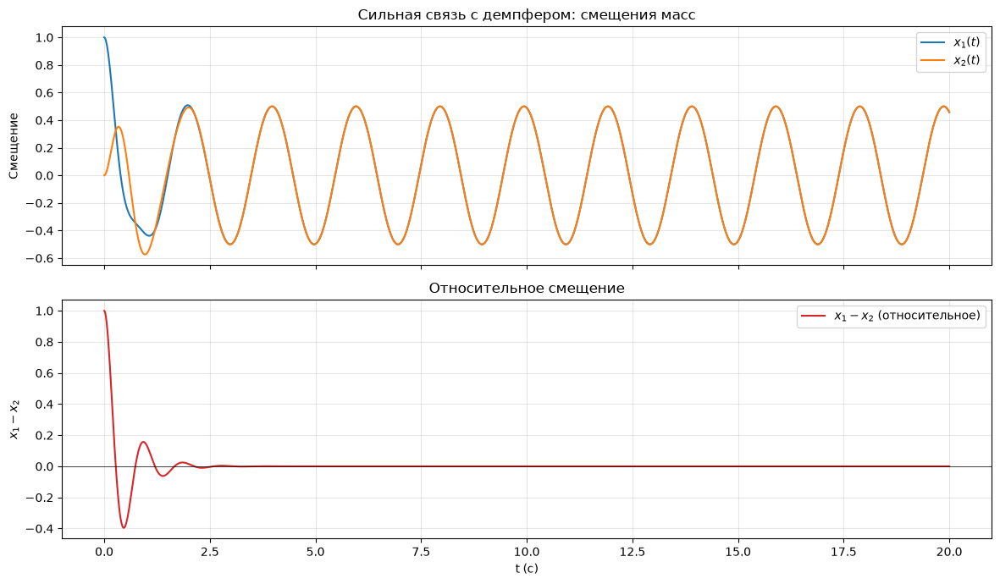

In [ ]:
# ============================================================
# Сильная связь + демпфер: RK4 и трапеции
# ============================================================
rhs_strong = make_rhs(k0_strong, kc_strong, c_strong)
step_rk4_strong = make_step_rk4(rhs_strong)

step_trap_picard = make_step_trap(rhs_strong)
step_trap_exact = make_step_trap_exact(A_strong)

step_trap_strong = step_trap_exact

dt_strong = 0.01
t_s, states_s = simulate(step_rk4_strong, s0, dt_strong, t_end=20.0)
x1_s = states_s[:, 0]
x2_s = states_s[:, 2]
diff_s = x1_s - x2_s

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t_s, x1_s, label=r'$x_1(t)$', color='tab:blue')
axes[0].plot(t_s, x2_s, label=r'$x_2(t)$', color='tab:orange')
axes[0].set_ylabel('Смещение')
axes[0].set_title('Сильная связь с демпфером: смещения масс')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(t_s, diff_s, label=r'$x_1 - x_2$ (относительное)', color='tab:red')
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xlabel('t (с)')
axes[1].set_ylabel(r'$x_1 - x_2$')
axes[1].set_title('Относительное смещение')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Анимация сильной связи + график x1 - x2

In [8]:
# ============================================================
# Анимация сильной связи с демпфером
# ============================================================
dt_anim2 = 0.01
t_anim2, states_anim2 = simulate(step_rk4_strong, s0, dt_anim2, t_end=20.0)
x1_anim2 = states_anim2[:, 0]
x2_anim2 = states_anim2[:, 2]
diff_anim2 = x1_anim2 - x2_anim2

fig, (ax_anim2, ax_plot2) = plt.subplots(2, 1, figsize=(10, 6),
                                          gridspec_kw={'height_ratios': [1, 1]})

ax_anim2.set_xlim(-2.5, 2.5)
ax_anim2.set_ylim(-0.5, 0.5)
ax_anim2.set_aspect('equal')
ax_anim2.axis('off')
ax_anim2.set_title('Анимация: сильная связь + демпфер')

ax_anim2.plot([-2.0, -2.0], [-0.3, 0.3], 'k-', lw=3)
ax_anim2.plot([ 2.0,  2.0], [-0.3, 0.3], 'k-', lw=3)

mass1_a, = ax_anim2.plot([], [], 'o', color='tab:blue',   markersize=25)
mass2_a, = ax_anim2.plot([], [], 'o', color='tab:orange', markersize=25)
spring1_a, = ax_anim2.plot([], [], 'k-', lw=1)
spring_mid_a, = ax_anim2.plot([], [], 'k--', lw=1)
spring2_a, = ax_anim2.plot([], [], 'k-', lw=1)

ax_plot2.set_xlim(0, 20)
ax_plot2.set_ylim(-1.2, 1.2)
ax_plot2.set_xlabel('t (с)')
ax_plot2.set_ylabel(r'$x_1 - x_2$')
ax_plot2.grid(alpha=0.3)
line_diff, = ax_plot2.plot([], [], color='tab:red', label=r'$x_1 - x_2$')
ax_plot2.legend(loc='upper right')

stride2 = 10
def update2(frame):
    i = frame * stride2
    if i >= len(t_anim2):
        i = len(t_anim2) - 1
    x1, x2 = x1_anim2[i], x2_anim2[i]
    p1 = -offset + x1
    p2 =  offset + x2
    mass1_a.set_data([p1], [0])
    mass2_a.set_data([p2], [0])
    spring1_a.set_data([-2.0, p1], [0, 0])
    spring_mid_a.set_data([p1, p2], [0, 0])
    spring2_a.set_data([p2, 2.0], [0, 0])
    line_diff.set_data(t_anim2[:i+1], diff_anim2[:i+1])
    return mass1_a, mass2_a, spring1_a, spring_mid_a, spring2_a, line_diff

n_frames2 = len(t_anim2) // stride2
anim_strong = animation.FuncAnimation(fig, update2, frames=n_frames2,
                                       interval=30, blit=True)
plt.close(fig)
HTML(anim_strong.to_jshtml())

# Сравнение RK4 и трапеций для разных шагов

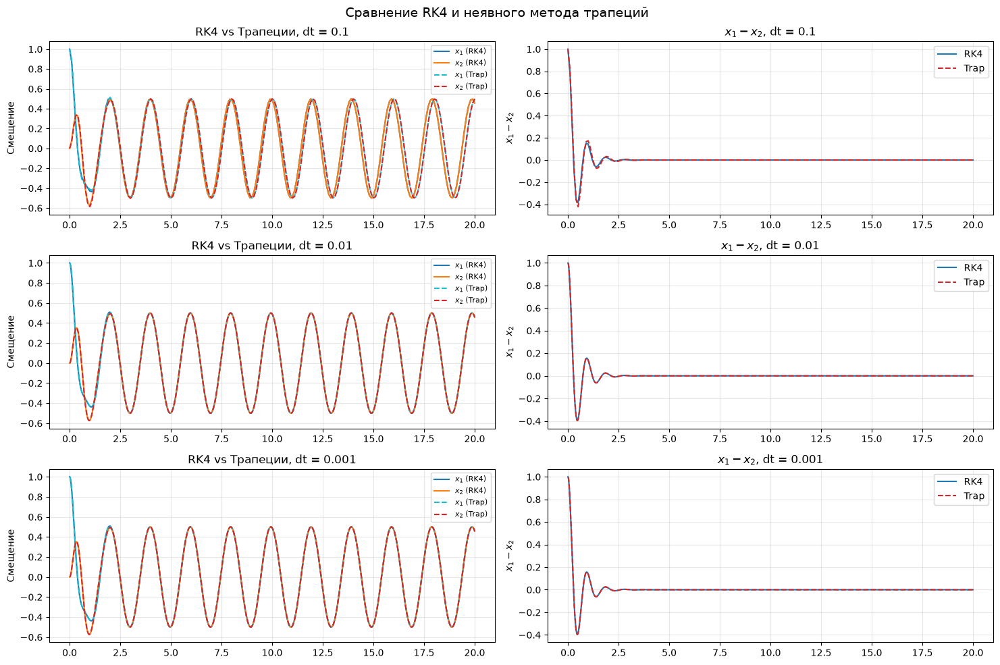

In [9]:
dt_list = [0.1, 0.01, 0.001]
t_end_cmp = 20.0

results = {}
for dt in dt_list:
    t_rk, s_rk = simulate(step_rk4_strong,  s0, dt, t_end_cmp)
    t_tr, s_tr = simulate(step_trap_strong, s0, dt, t_end_cmp)
    results[dt] = {
        'RK4': (t_rk, s_rk),
        'Trap': (t_tr, s_tr)
    }

fig, axes = plt.subplots(len(dt_list), 2, figsize=(15, 10))

for i, dt in enumerate(dt_list):
    t_rk, s_rk = results[dt]['RK4']
    t_tr, s_tr = results[dt]['Trap']
    x1_rk, x2_rk = s_rk[:, 0], s_rk[:, 2]
    x1_tr, x2_tr = s_tr[:, 0], s_tr[:, 2]
    
    axes[i, 0].plot(t_rk, x1_rk, label=r'$x_1$ (RK4)',  color='tab:blue')
    axes[i, 0].plot(t_rk, x2_rk, label=r'$x_2$ (RK4)',  color='tab:orange')
    axes[i, 0].plot(t_tr, x1_tr, '--', label=r'$x_1$ (Trap)', color='tab:cyan')
    axes[i, 0].plot(t_tr, x2_tr, '--', label=r'$x_2$ (Trap)', color='tab:red')
    axes[i, 0].set_title(f'RK4 vs Трапеции, dt = {dt}')
    axes[i, 0].set_ylabel('Смещение')
    axes[i, 0].legend(fontsize=8)
    axes[i, 0].grid(alpha=0.3)
    
    # Относительное смещение
    diff_rk = x1_rk - x2_rk
    diff_tr = x1_tr - x2_tr
    axes[i, 1].plot(t_rk, diff_rk, label='RK4',  color='tab:blue')
    axes[i, 1].plot(t_tr, diff_tr, '--', label='Trap', color='tab:red')
    axes[i, 1].set_title(f'$x_1 - x_2$, dt = {dt}')
    axes[i, 1].set_ylabel(r'$x_1 - x_2$')
    axes[i, 1].legend()
    axes[i, 1].grid(alpha=0.3)

plt.suptitle('Сравнение RK4 и неявного метода трапеций', fontsize=14)
plt.tight_layout()
plt.show()

# Переходный процесс vs медленное движение + увеличение шага

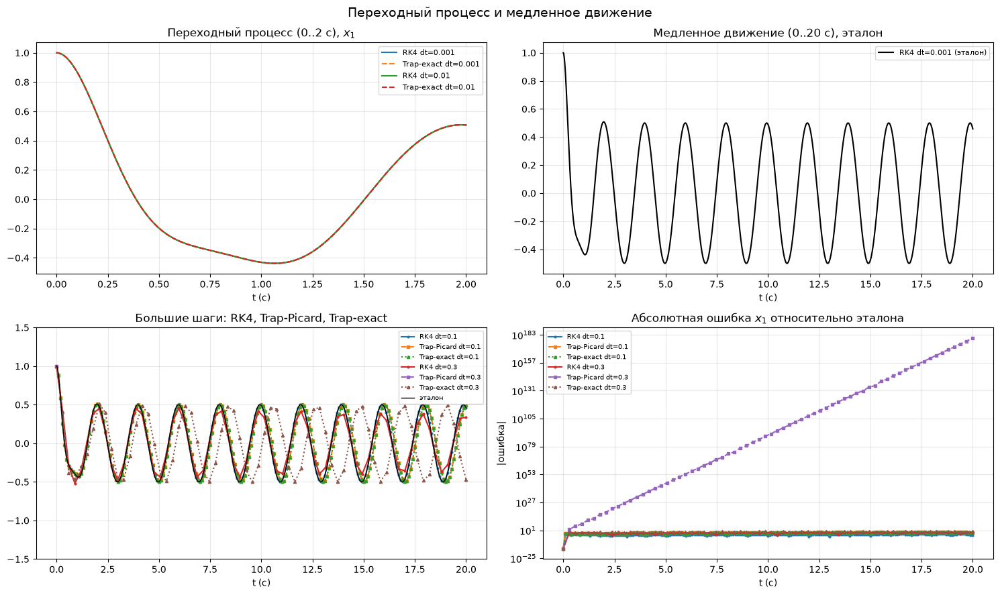

--- Ошибка Trap-exact при dt = 0.1 ---
  Максимальная ошибка   = 2.476e-01
  Средняя ошибка        = 8.238e-02

--- Ошибка Trap-Picard при dt = 0.1 ---
  Максимальная ошибка   = 2.476e-01
  Средняя ошибка        = 8.238e-02

--- Порог сходимости простых итераций ---
  dt* = 2/|lambda_max| = 0.2828 с
  При dt = 0.3 > dt*: Trap-Picard расходится, Trap-exact устойчив.

--- Порядок метода трапеций ---
  dt = 0.1000: max err = 2.476e-01
  dt = 0.0100: max err = 2.553e-03
  dt = 0.0010: max err = 2.553e-05

--- Оценка порядка метода ---
  dt 0.1 -> 0.01: p ≈ 1.99
  dt 0.01 -> 0.001: p ≈ 2.00

--- Ошибка RK4 при dt = 0.1 ---
  Максимальная ошибка = 2.541e-03
  Средняя ошибка      = 8.908e-04


In [16]:
# ============================================================
# Переходный процесс (0..2 с) vs медленное движение (0..20 с)
# ============================================================
t_trans_end = 2.0
t_slow_end  = 20.0

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# ---------- (0,0) Переходный процесс: RK4 vs Trap-exact ----------
for dt in [0.001, 0.01]:
    t_tr, s_tr = simulate(step_rk4_strong, s0, dt, t_trans_end)
    axes[0, 0].plot(t_tr, s_tr[:, 0], label=f'RK4 dt={dt}')
    t_tp, s_tp = simulate(step_trap_exact, s0, dt, t_trans_end)
    axes[0, 0].plot(t_tp, s_tp[:, 0], '--', label=f'Trap-exact dt={dt}')
axes[0, 0].set_title('Переходный процесс (0..2 с), $x_1$')
axes[0, 0].set_xlabel('t (с)'); axes[0, 0].legend(fontsize=8); axes[0, 0].grid(alpha=0.3)

# ---------- (0,1) Медленное движение: эталон ----------
t_slow, s_slow = simulate(step_rk4_strong, s0, 0.001, t_slow_end)
axes[0, 1].plot(t_slow, s_slow[:, 0], label='RK4 dt=0.001 (эталон)', color='k')
axes[0, 1].set_title('Медленное движение (0..20 с), эталон')
axes[0, 1].set_xlabel('t (с)'); axes[0, 1].legend(fontsize=8); axes[0, 1].grid(alpha=0.3)

# ---------- (1,0) Большие шаги: RK4 vs Trap-Picard vs Trap-exact ----------
# Здесь специально включаю dt = 0.3, чтобы показать расходимость Trap-Picard
for dt_big in [0.1, 0.3]:
    # RK4
    t_big, s_big = simulate(step_rk4_strong, s0, dt_big, t_slow_end)
    axes[1, 0].plot(t_big, s_big[:, 0], 'o-', ms=2, label=f'RK4 dt={dt_big}')

    # Trap-Picard (может взорваться при dt >= 0.283)
    t_pic, s_pic = simulate(step_trap_picard, s0, dt_big, t_slow_end)

    mask = np.abs(s_pic[:, 0]) < 10
    axes[1, 0].plot(t_pic[mask], s_pic[mask, 0], 's--', ms=3,
                    label=f'Trap-Picard dt={dt_big}')

    # Trap-exact (A-устойчив при любом dt)
    t_ex, s_ex = simulate(step_trap_exact, s0, dt_big, t_slow_end)
    axes[1, 0].plot(t_ex, s_ex[:, 0], '^:', ms=3,
                    label=f'Trap-exact dt={dt_big}')

axes[1, 0].plot(t_slow, s_slow[:, 0], 'k-', lw=1, label='эталон')
axes[1, 0].set_title('Большие шаги: RK4, Trap-Picard, Trap-exact')
axes[1, 0].set_xlabel('t (с)'); axes[1, 0].legend(fontsize=7); axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_ylim(-1.5, 1.5)

# ---------- (1,1) Ошибка относительно эталона ----------
for dt_big in [0.1, 0.3]:
    # RK4
    t_big, s_big = simulate(step_rk4_strong, s0, dt_big, t_slow_end)
    s_ref = np.interp(t_big, t_slow, s_slow[:, 0])
    axes[1, 1].semilogy(t_big, np.abs(s_big[:, 0] - s_ref) + 1e-16,
                        'o-', ms=2, label=f'RK4 dt={dt_big}')

    # Trap-Picard
    t_pic, s_pic = simulate(step_trap_picard, s0, dt_big, t_slow_end)
    s_ref_pic = np.interp(t_pic, t_slow, s_slow[:, 0])
    err_pic = np.abs(s_pic[:, 0] - s_ref_pic) + 1e-16
    axes[1, 1].semilogy(t_pic, err_pic, 's--', ms=3,
                        label=f'Trap-Picard dt={dt_big}')

    # Trap-exact
    t_ex, s_ex = simulate(step_trap_exact, s0, dt_big, t_slow_end)
    s_ref_ex = np.interp(t_ex, t_slow, s_slow[:, 0])
    axes[1, 1].semilogy(t_ex, np.abs(s_ex[:, 0] - s_ref_ex) + 1e-16,
                        '^:', ms=3, label=f'Trap-exact dt={dt_big}')

axes[1, 1].set_title('Абсолютная ошибка $x_1$ относительно эталона')
axes[1, 1].set_xlabel('t (с)'); axes[1, 1].set_ylabel('|ошибка|')
axes[1, 1].legend(fontsize=7); axes[1, 1].grid(alpha=0.3, which='both')

plt.suptitle('Переходный процесс и медленное движение', fontsize=14)
plt.tight_layout()
plt.show()

# ============================================================
# Численная оценка ошибки трапеций при dt = 0.1
# ============================================================
t_ex, s_ex = simulate(step_trap_exact, s0, 0.1, t_slow_end)
s_ref_ex = np.interp(t_ex, t_slow, s_slow[:, 0])
err_ex = np.abs(s_ex[:, 0] - s_ref_ex)

print("--- Ошибка Trap-exact при dt = 0.1 ---")
print(f"  Максимальная ошибка   = {err_ex.max():.3e}")
print(f"  Средняя ошибка        = {err_ex.mean():.3e}")

t_pic, s_pic = simulate(step_trap_picard, s0, 0.1, t_slow_end)
s_ref_pic = np.interp(t_pic, t_slow, s_slow[:, 0])
err_pic = np.abs(s_pic[:, 0] - s_ref_pic)

print("\n--- Ошибка Trap-Picard при dt = 0.1 ---")
print(f"  Максимальная ошибка   = {err_pic.max():.3e}")
print(f"  Средняя ошибка        = {err_pic.mean():.3e}")

print(f"\n--- Порог сходимости простых итераций ---")
print(f"  dt* = 2/|lambda_max| = {dt_star:.4f} с")
print(f"  При dt = 0.3 > dt*: Trap-Picard расходится, Trap-exact устойчив.")

# ============================================================
# Проверка порядка метода трапеций
# ============================================================
print("\n--- Порядок метода трапеций ---")
errors = {}
for dt in [0.1, 0.01, 0.001]:
    t_ex, s_ex = simulate(step_trap_exact, s0, dt, t_slow_end)
    s_ref_ex = np.interp(t_ex, t_slow, s_slow[:, 0])
    err_ex = np.abs(s_ex[:, 0] - s_ref_ex)
    errors[dt] = err_ex.max()
    print(f"  dt = {dt:.4f}: max err = {err_ex.max():.3e}")

# Оценка порядка
print("\n--- Оценка порядка метода ---")
dts = [0.1, 0.01, 0.001]
for i in range(len(dts)-1):
    dt1, dt2 = dts[i], dts[i+1]
    e1, e2 = errors[dt1], errors[dt2]
    p = np.log(e1/e2) / np.log(dt1/dt2)
    print(f"  dt {dt1} -> {dt2}: p ≈ {p:.2f}")

# ============================================================
# Ошибка RK4 при dt = 0.1 (для сравнения с трапециями)
# ============================================================
t_rk, s_rk = simulate(step_rk4_strong, s0, 0.1, t_slow_end)
s_ref_rk = np.interp(t_rk, t_slow, s_slow[:, 0])
err_rk = np.abs(s_rk[:, 0] - s_ref_rk)

print("\n--- Ошибка RK4 при dt = 0.1 ---")
print(f"  Максимальная ошибка = {err_rk.max():.3e}")
print(f"  Средняя ошибка      = {err_rk.mean():.3e}")

In [12]:
# Проверка: что происходит с Trap-Picard при dt = 0.3?
t_pic, s_pic = simulate(step_trap_picard, s0, 0.3, t_slow_end)
print(f"\n--- Trap-Picard при dt = 0.3 ---")
print(f"  max |x1| = {np.max(np.abs(s_pic[:, 0])):.3e}")
print(f"  Взрыв? {'ДА' if np.max(np.abs(s_pic[:, 0])) > 1e3 else 'НЕТ'}")

t_ex, s_ex = simulate(step_trap_exact, s0, 0.3, t_slow_end)
print(f"\n--- Trap-exact при dt = 0.3 ---")
print(f"  max |x1| = {np.max(np.abs(s_ex[:, 0])):.3e}")
print(f"  Взрыв? {'ДА' if np.max(np.abs(s_ex[:, 0])) > 1e3 else 'НЕТ'}")


--- Trap-Picard при dt = 0.3 ---
  max |x1| = 1.005e+180
  Взрыв? ДА

--- Trap-exact при dt = 0.3 ---
  max |x1| = 1.000e+00
  Взрыв? НЕТ


## Ответ на главный вопрос

**Можно ли после затухания быстрой моды увеличить шаг?**

**Да, но точность при этом падает.** После $t \gtrsim 2$ с быстрая мода ($\omega_2 = 7.07$ рад/с) затухает, остаётся медленная ($\omega_1 = 3.16$ рад/с, $T_1 \approx 2$ с).

**Ошибка трапеций (точный решатель) растёт как $O(dt^2)$:**

| $dt$   | Ошибка (макс.)           | Порядок $p$ |
|--------|--------------------------|-------------|
| 0.1    | $2.476 \times 10^{-1}$   | —           |
| 0.01   | $2.553 \times 10^{-3}$   | 1.99        |
| 0.001  | $2.553 \times 10^{-5}$   | 2.00        |
| RK4 0.1| $2.541 \times 10^{-3}$   | —           |

Оценка порядка $p \approx 2$ подтверждает 2-й порядок метода трапеций.

- При $dt = 0.3$: `Trap-Picard` даёт $\max|x_1| \sim 10^{180}$ (взрыв), `Trap-exact` — $\max|x_1| \sim 1$ (устойчиво).
- **RK4** при $dt = 0.1$ даёт меньшую ошибку, чем трапеции, — для больших шагов RK4 предпочтительнее.